---

MRI analysis 

---

In [1]:
# autoload
%load_ext autoreload
%autoreload 2
from pgl import pgl, pglDatabase, pglActions, pglFlywheel, pglAFNI, pglActionsMRI, pglActionsMNE, pglActionsFixes


---

Load behavioral data

---

In [ ]:
pgl.importSettings()

In [2]:
newSession = pglActions.loadSession.execute()
if newSession: 
    session = newSession
    session.print()

=================================== Session ====================================
  Source checkpoint : Not set
  Runs              : 10
  Filesystem        : file, local
  MEG/EEG data      : None
  MRI data          : None

---------------------------- Experiment and subject ----------------------------
  nsd-mini / sdbp_nsdmini_0002

------------------------------------ Run 1 -------------------------------------
Experiment: nsd-mini | Subject ID: sdbp_nsdmini_0002
Session: session_2026-11-13 | Run: run_12-28-39
2026-11-13T12:32:11.679832-08:00
Duration: 6 mins 16s
Number of volume triggers: 240
Median time between triggers: 1.510s
Mean ± std time between triggers: 1.569 ± 0.870336s
Suspected manual final trigger: trigger 240, gap=14.835s; excluded from missing-volume and timing-discrepancy counts.
Duration and interval statistics above still include this final trigger.
Possible missing volumes = 2
No interval timing discrepancies ≥100 ms detected, excluding any suspected manual fina

In [3]:
fixVolumeTimes = pglActionsFixes.fixVolumeTimes()
newSession = fixVolumeTimes.execute(session=session)
if newSession: 
    session = newSession
    session.print()

(pglActionsFixes:_printPlan) Run 0: median volume time=1.510000 s; correction threshold=20 ms.
(pglActionsFixes:_printPlan)   Correct isolated triggers only when their original neighboring triggers predict times agreeing within 20 ms.
(pglActionsFixes:_printPlan)   Missing triggers are interpolated between retained anchors; persistent timing shifts are not propagated or
regularized.
(pglActionsFixes:_printPlan)   Volumes: 240 → 242; insert=2, adjust=0, remove=0.
(pglActionsFixes:_printPlan)   Final trigger excluded from automatic repair because its gap may reflect a manual ending trigger. Explicit
count/boundary edits still apply.
(pglActionsFixes:_printPlan)   If retained, this final trigger still contributes to the current print summary's timing statistics.
(pglMessages:warning) ❌ Run 0: 32 interval timing discrepancies remain before boundary edits (insufficient support for an isolated correction).
These were not fixed and may still be flagged by print()/display(). ❌
(pglActionsFixes

In [ ]:
session.display()

In [ ]:
session.print()

---

Load data from flywheel

---

In [ ]:
# logkn to flywheel (just for testing)
flywheel = pglFlywheel()

In [4]:
newSession = pglActions.loadFlywheel().execute(session=session, showScanCounts=False)
if newSession: 
    session = newSession
    session.print()

(pglFlywheel:__init__) Logged in as: Justin Gardner (jlg@stanford.edu)
(pglFlywheelProject:loadedSessions) Loading sessions: babybrains
(pglFlywheelSession:loadedScans) Loading scans: 2020-03-04 21:52 PST
(pglFlywheelProject:loadedSessions) Loading sessions: DigitalBrainsPilot
(pglFlywheelSession:loadedScans) Loading scans: 2026-02-11 14:10 UTC
(pglFlywheelSession:loadedScans) Loading scans: 2026-11-13 12:08 PST


             0% [   00:00<       ?] Preparing deferred Flywheel MRI scans

(loadFlywheel:_run) Attaching 48 deferred MRI scan(s) from Flywheel project '698b820dde4a9c690173d3e0', session '6af770dc92f0d6de8cd6296f',
to the existing session.
(loadFlywheel:_run) Preserving 10 behavioral run(s), existing labels, and other session contents. Scan-to-run alignment is not performed.
=================================== Session ====================================
  Source checkpoint : Not set
  Runs              : 10
  Filesystem        : file, local
  MEG/EEG data      : None
  MRI data          : 48 scans

---------------------------- Experiment and subject ----------------------------
  nsd-mini / sdbp_nsdmini_0002

------------------------------------ Run 1 -------------------------------------
Experiment: nsd-mini | Subject ID: sdbp_nsdmini_0002
Session: session_2026-11-13 | Run: run_12-28-39
2026-11-13T12:32:11.679832-08:00
Duration: 6 mins 16s
Number of volume triggers: 242
Median time between triggers: 1.510s
Mean ± std time between triggers: 1.556 ± 0.857451s

In [12]:
session.mri.print(match='nsdmini')

10 of 48 MRI scans matched 'nsdmini'.


             0% [   00:00<       ?] Gathering MRI scan information

 5: nsdmini_run01_bold_1p4mm_R3x3_esp570_TR1510  12:32  dims=[144, 144, 96, 241]  voxelDims=[1.38889, 1.38889, 1.4]mm  fov=[200, 200, 134.4]mm  size=500 MB  11/13/2026 (PST) : 1_3_12_2_1107_5_2_61_251202_2026111312313389043002453_0_0_0.nii.gz
 6: nsdmini_run02_bold_1p4mm_R3x3_esp570_TR1510  12:39  dims=[144, 144, 96, 242]  voxelDims=[1.38889, 1.38889, 1.4]mm  fov=[200, 200, 134.4]mm  size=500 MB  11/13/2026 (PST) : 1_3_12_2_1107_5_2_61_251202_2026111312390826805148970_0_0_0.nii.gz
 7: nsdmini_run03_bold_1p4mm_R3x3_esp570_TR1510  12:47  dims=[144, 144, 96, 242]  voxelDims=[1.38889, 1.38889, 1.4]mm  fov=[200, 200, 134.4]mm  size=500 MB  11/13/2026 (PST) : 1_3_12_2_1107_5_2_61_251202_2026111312462955688695680_0_0_0.nii.gz
11: nsdmini_run04_bold_1p4mm_R3x3_esp570_TR1510  13:00  dims=[144, 144, 96, 242]  voxelDims=[1.38889, 1.38889, 1.4]mm  fov=[200, 200, 134.4]mm  size=500 MB  11/13/2026 (PST) : 1_3_12_2_1107_5_2_61_251202_2026111313000558168646550_0_0_0.nii.gz
12: nsdmini_run05_bold_1p4mm

MRI shift: -0.960 sec


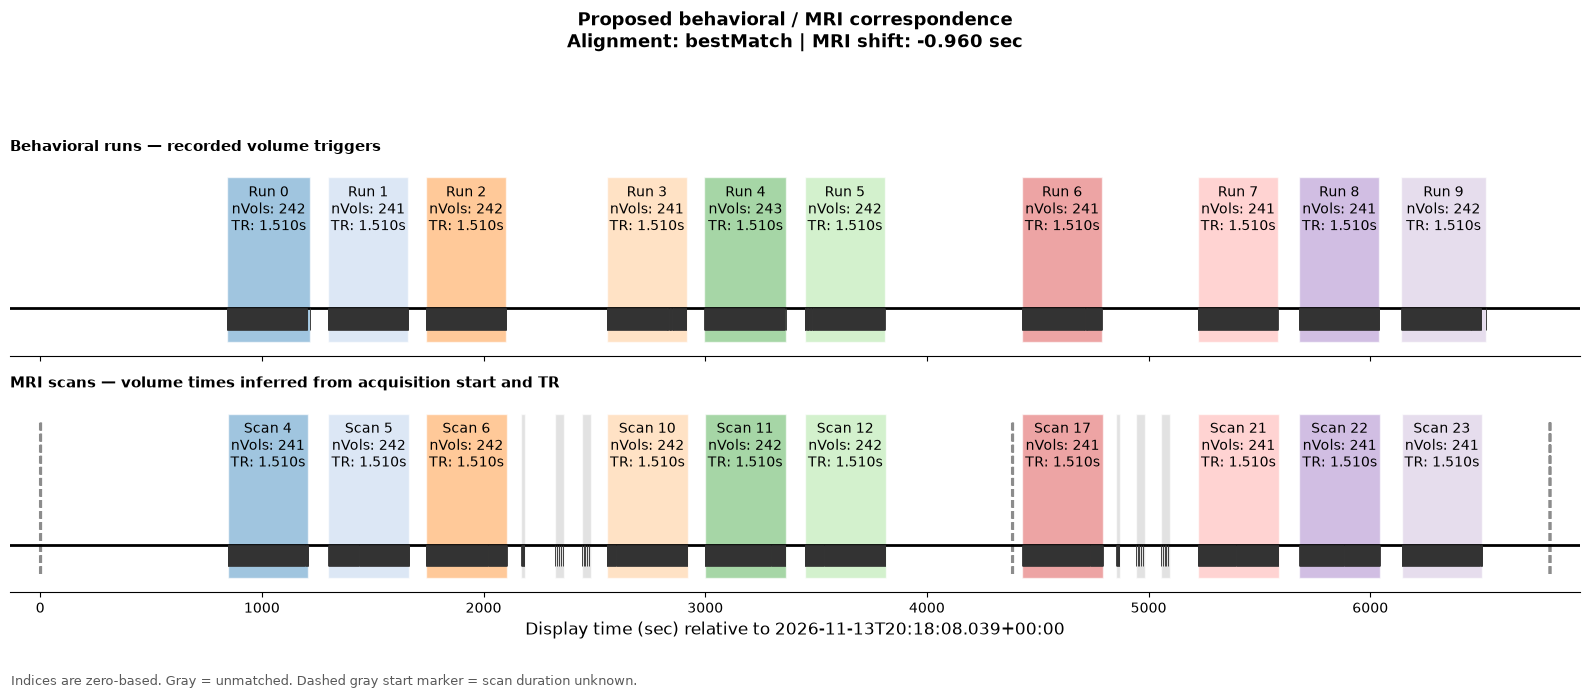

In [7]:
from pgl.pglPlots import pglScanTimelinePlot

# Zero-based (scanIndex, runIndex) pairs.
# Scan 0, the T1, remains unmatched.
proposedMatch = [(4, 0), (5, 1), (6, 2), (10, 3), (11, 4), (12, 5), (17,6), (21, 7), (22, 8), (23, 9)]

timeline = pglScanTimelinePlot(
    pglRuns=session.runs,
    pglScans=session.mri.scans,
    proposedMatch=proposedMatch,
    alignmentMode='bestMatch',
    volumeMarkerStyle='tick'
)

print(f"MRI shift: {timeline.getAlignmentOffset():+.3f} sec")
timeline.show()

In [10]:
for scanIndex, runIndex in proposedMatch:
    scan = session.mri.scans[scanIndex]
    summary = scan.getScanSummary(readHeaders=True)

    print(f"\nScan {scanIndex}: {scan.name} → Run {runIndex}")
    print(f"  scanDims:  {summary.get('scanDims')!r}")
    print(f"  trSeconds: {summary.get('trSeconds')!r}")


Scan 1: AAhead_scout_AA_MPR_sag: AAhead_scout_AA_MPR_sag.nii.gz → Run 0
  scanDims:  [5, 162, 162, 1]
  trSeconds: None

Scan 2: AAhead_scout_AA_MPR_cor: AAhead_scout_AA_MPR_cor.nii.gz → Run 1
  scanDims:  [162, 3, 162, 1]
  trSeconds: None

Scan 3: AAhead_scout_AA_MPR_tra: AAhead_scout_AA_MPR_tra.nii.gz → Run 2
  scanDims:  [162, 162, 3, 1]
  trSeconds: None


In [ ]:
session.mri.print(match='nsdmini')

---

AFNI: check availability and optional install

---

In [ ]:
afni = pglAFNI(directory="~/proj/afni/abin")
available = afni.checkAvailable("3dvolreg")

In [ ]:
afni = pglAFNI()
afni.install()

In [ ]:
pglActions.help()
